# Family haplotypes under biased sampling: population priors, recombination and identifiability

Family studies of a linked region (a disease haplotype block, an HLA-like
region, a carrier-screening panel) ask three kinds of questions:

1. **Population questions** — how frequent is each haplotype in the
   population, and how does that depend on a person's ancestry and on the
   founder community a family comes from?
2. **Meiosis questions** — how often, and where, does a crossover happen
   when a parent transmits the region?
3. **Family questions** — which pair of haplotypes does each parent carry,
   and is that joint parental state *determined* by the hard evidence?

Three facts make these harder than they look:

* **Families are not a random sample.** Clinics recruit affected / carrier
  families more often, and only a random subset of the recruited families is
  phase-validated (a second, randomised sampling phase). Population
  estimates must undo *both* phases: weight each phased family by
  $1/(\pi_\text{inclusion}\,\pi_\text{validation})$ (Horvitz & Thompson 1952;
  the two-phase design of Breslow & Wellner 2007). The sampling
  probabilities are *weights*, never covariates of the population model.
* **The prior depends on covariates in an unknown way.** Haplotype
  frequencies vary smoothly but non-linearly with ancestry, and families
  from one founder community share a latent haplotype profile — so the two
  parents of a family are *not* independent draws. `fit_haplotype_prior`
  models this as latent shared-family classes (mixing depends on a noisy
  community label) with a penalised multinomial-logit surface on the
  covariates, and lets held-out families decide the number of classes, the
  basis and the penalty.
* **A certificate is not a posterior.** "Identifiable" means exactly one
  joint parental state is compatible with all high-confidence evidence
  (parents' copy numbers and every child explained by some transmission with
  at most one crossover). It is a combinatorial statement, computed exactly
  by `structural_identifiability` — not "the MAP state has posterior > x".

All numerics live in a numpy/scipy-only core, so a pipeline that must run
without omicverse can embed it (`pedigree_core_source`). This notebook uses
simulated families with a known truth, so every estimate can be checked.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import omicverse as ov

ov.plot_set()
np.set_printoptions(precision=4, suppress=True)

🔬 Starting plot initialization...
🧬 Detecting GPU devices…
🚫 No GPU devices found (CUDA/MPS/ROCm/XPU)

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

🔖 Version: 2.3.2   📚 Tutorials: https://omicverse.readthedocs.io/
✅ plot_set complete.



## 1. A simulated family cohort with a known truth

`simulate_family_cohort` draws a population of couples. Each family has a
latent founder class $c$ and a noisy community label (correct with
probability `group_accuracy`); each parent has ancestry proportions $x$
(Dirichlet) and two haplotypes drawn i.i.d. from
$\mathrm{softmax}(\text{class profile}_c + f(x))$ with a smooth non-linear
$f$. Families enter the study with a probability that depends on carrying
the allele at the first locus (ascertainment), and 30 % of the recruited
families are phase-validated. Children receive one gamete per parent with at
most one crossover.

In [2]:
sim = ov.genetics.simulate_family_cohort(n_families=4000, n_loci=10, n_haplotypes=30,
                                         n_classes=3, ascertainment_strength=2.0,
                                         second_phase_prob=0.3, seed=3)
fam = {f["family_id"]: f for f in sim["families"]}
people = sim["people"]
validated = [p for p in people if fam[p["family_id"]]["validated"]]
print(f"population families: 4000   recruited: {len(fam)}   phase-validated: "
      f"{sum(f['validated'] for f in fam.values())}   children: {len(sim['children'])}")
print("catalog size:", len(sim["catalog"]), " e.g.", sim["catalog"][:3])

population families: 4000   recruited: 2115   phase-validated: 668   children: 3218
catalog size: 30  e.g. ['0000000000', '0000001000', '0000010001']


## 2. Population haplotype frequencies: undo both sampling phases

Each phased parent contributes its two haplotypes with weight
$w = 1/(\pi_1\pi_2)$. The Hájek estimator
$\hat p_h = \sum_i w_i (1[a_i=h]+1[b_i=h]) / (2\sum_i w_i)$ is consistent for
the population *before* recruitment; the unweighted count is consistent for
the recruited-and-validated families, which over-represent carriers.

In [3]:
w = ov.genetics.two_phase_weights([fam[p["family_id"]]["first_phase_prob"] for p in validated],
                                  [fam[p["family_id"]]["second_phase_prob"] for p in validated])
hap1 = [p["hap_a"] for p in validated]
hap2 = [p["hap_b"] for p in validated]
truth = dict(zip(sim["catalog"], sim["true_population_freq"]))


def total_variation(catalog, freq):
    est = dict(zip(catalog, freq))
    return 0.5 * sum(abs(truth.get(h, 0) - est.get(h, 0)) for h in set(truth) | set(est))


cat_w, f_w = ov.genetics.haplotype_frequencies(hap1, hap2, weights=w)
cat_u, f_u = ov.genetics.haplotype_frequencies(hap1, hap2)
print(f"total variation to the population truth: weighted {total_variation(cat_w, f_w):.3f}"
      f"   unweighted {total_variation(cat_u, f_u):.3f}")
carrier = np.array([h[0] == "1" for h in cat_w])
print(f"frequency of haplotypes carrying the ascertained allele: truth "
      f"{sum(truth[h] for h in cat_w if h[0] == '1'):.3f}  weighted {f_w[carrier].sum():.3f}"
      f"  unweighted {f_u[carrier].sum():.3f}")

total variation to the population truth: weighted 0.038   unweighted 0.096
frequency of haplotypes carrying the ascertained allele: truth 0.460  weighted 0.452  unweighted 0.527


The unweighted estimate inflates exactly the haplotypes that drove
recruitment. Weights must be per *family* (both parents share the family's
inclusion probabilities); `trim_quantile` can cap extreme weights when a few
families have tiny inclusion probabilities (a small bias for a large
variance reduction).

## 3. A covariate- and community-dependent population prior

`fit_haplotype_prior` takes the phased parents (two haplotypes each), their
covariates, family ids (members of a family share the latent class), the
family-level group label and the design weights. It

1. chooses the number of latent classes from the co-occurrence of the four
   parental haplotypes of each family (mixture of multinomials, class
   mixing per group label),
2. fits, within classes, a penalised multinomial-logit surface on the
   standardised covariates — constant, linear, quadratic or quadratic + RBF;
   either one surface shared by all classes plus class-specific profiles, or
   one surface per class,
3. scores every candidate by design-weighted held-out *family*
   log-likelihood (families are never split), keeps the simplest candidate
   within one standard error of the best, refits it on all families and
   refines the class responsibilities by EM.

In [4]:
x = np.array([p["x"] for p in validated])
prior = ov.genetics.fit_haplotype_prior(hap1, hap2, x, [p["family_id"] for p in validated],
                                        groups=[p["group"] for p in validated], weights=w)
sel = prior.selection
print({k: sel[k] for k in ("n_components", "basis", "interaction", "penalty", "n_families",
                           "n_holdout_families")})
import pandas as pd
pd.DataFrame(sel["stage_surface"]).sort_values("mean", ascending=False).head(8)

{'n_components': 3, 'basis': 'linear', 'interaction': 'shared', 'penalty': 0.1, 'n_families': 668, 'n_holdout_families': 123}


            basis interaction  penalty      mean
29  quadratic_rbf      shared     0.03 -5.797237
17      quadratic      shared     0.03 -5.808894
5          linear      shared     0.03 -5.809073
28  quadratic_rbf      shared     0.10 -5.812373
30  quadratic_rbf      shared     0.01 -5.816232
16      quadratic      shared     0.10 -5.820470
6          linear      shared     0.01 -5.821116
18      quadratic      shared     0.01 -5.833015

Compare the learned prior with the generating one at new ancestries, and
with the ancestry-naive weighted frequencies of section 2:

In [5]:
rng = np.random.default_rng(0)
x_new = rng.dirichlet(np.ones(3), size=300)
g_new = [f"G{1 + i % 3}" for i in range(300)]
order = [sim["catalog"].index(h) for h in prior.catalog]
naive = np.array([dict(zip(cat_w, f_w))[h] for h in prior.catalog])
err_model, err_naive = [], []
for xi, g in zip(x_new, g_new):
    true = sim["true_haplotype_probs"](xi[None], g)[0][order]
    err_model.append(prior.haplotype_probs(xi[None], g)[0] - true)
    err_naive.append(naive - true)
print(f"RMSE of p(h | ancestry, community): learned prior {np.sqrt(np.mean(np.square(err_model))):.4f}"
      f"   ancestry-naive frequencies {np.sqrt(np.mean(np.square(err_naive))):.4f}")

RMSE of p(h | ancestry, community): learned prior 0.0183   ancestry-naive frequencies 0.0510


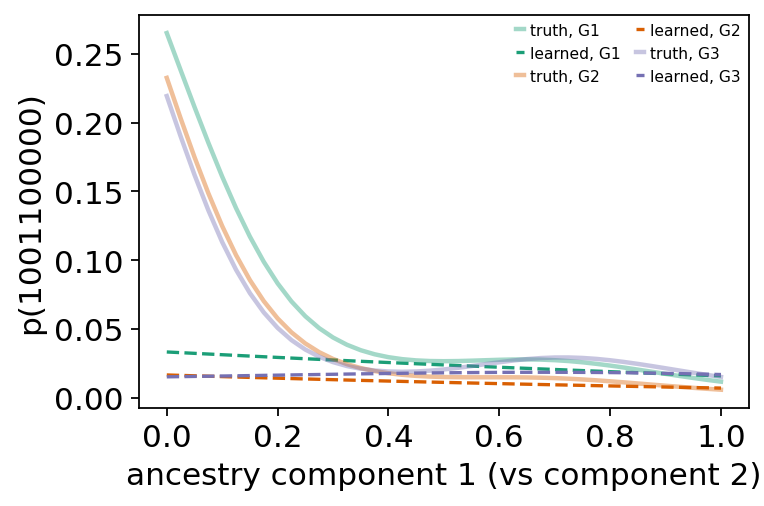

In [6]:
h = int(np.argmax(np.ptp([sim["true_haplotype_probs"](np.array([[t, 1 - t, 0.0]]))[0]
                          for t in np.linspace(0, 1, 11)], axis=0)))
hap = sim["catalog"][h]
t = np.linspace(0, 1, 41)
xs = np.c_[t, 1 - t, np.zeros_like(t)] * 0.9 + 0.1 / 3
fig, ax = plt.subplots(figsize=(5, 3.4))
for g, color in zip(["G1", "G2", "G3"], ["#1b9e77", "#d95f02", "#7570b3"]):
    ax.plot(t, sim["true_haplotype_probs"](xs, g)[:, h], color=color, lw=2, alpha=0.4,
            label=f"truth, {g}")
    ax.plot(t, prior.haplotype_probs(xs, g)[:, prior.catalog.index(hap)], color=color, ls="--",
            label=f"learned, {g}")
ax.set_xlabel("ancestry component 1 (vs component 2)")
ax.set_ylabel(f"p({hap})")
ax.legend(fontsize=7, ncol=2, frameon=False)
plt.tight_layout()

### Parents are dependent through the shared class

Given the mother's diplotype, the class posterior of the family shifts, and
with it the father's prior:
$P(\text{father}\mid\text{mother}) = \sum_c P(c\mid g,\text{mother})\,P(\text{father}\mid c, x_f)$.
`joint_diplotype_prior` gives the same joint prior for whole candidate
lists (what a family posterior multiplies with the genotype likelihoods).

In [7]:
mother = validated[0]
father = [p for p in validated if p["family_id"] == mother["family_id"] and p["role"] == "paternal"][0]
m_pair = (mother["hap_a"], mother["hap_b"])
f_pair = (father["hap_a"], father["hap_b"])
print("class mixing for this community:", prior.mixing(mother["group"]))
print("class posterior given the mother:", prior.class_posterior([(mother["x"], m_pair)], mother["group"]))
print(f"P(father = {f_pair}) marginal {prior.diplotype_prob(f_pair, father['x'], father['group']):.4g}"
      f"   given the mother {prior.conditional_diplotype_prob(f_pair, father['x'], m_pair, mother['x'], mother['group']):.4g}")
joint = prior.joint_diplotype_prior([mother["x"], father["x"]], [[m_pair], [f_pair]], mother["group"])
print("joint prior of the (mother, father) state:", joint)

class mixing for this community: [0.2971 0.469  0.2339]
class posterior given the mother: [0.0073 0.4973 0.4954]
P(father = ('0000110000', '1000001010')) marginal 0.02861   given the mother 0.03034
joint prior of the (mother, father) state: [[0.0008]]


**Population frequencies from the model.** When the covariates of *all*
recruited parents are known (not only the validated ones), averaging the
fitted prior over them with first-phase weights $1/\pi_1$ uses much more
data than the validated-only Hájek estimate:

In [8]:
x_all = np.array([p["x"] for p in people])
g_all = [p["group"] for p in people]
w_all = np.array([1 / fam[p["family_id"]]["first_phase_prob"] for p in people])
f_model = prior.population_average(x_all, g_all, w_all)
print(f"total variation: model average {total_variation(prior.catalog, f_model):.3f}   "
      f"Hajek {total_variation(cat_w, f_w):.3f}")

total variation: model average 0.034   Hajek 0.038


## 4. Crossover masses per interval

A meiosis starts on either homologue with probability 1/2 and has no
crossover (mass $m_0$) or one crossover in interval $j$ (mass $m_j$). When
the two homologues share alleles around a cut, one transmitted sequence is
consistent with several categories; counting it as a hard event biases both
$m_0$ and the interval allocation. `fit_crossover_intervals` marginalises
these ambiguities by EM (with Dirichlet smoothing chosen on held-out
families). Fit maternal and paternal meioses separately — their rates differ.

no-crossover mass: estimate 0.604  truth 0.600


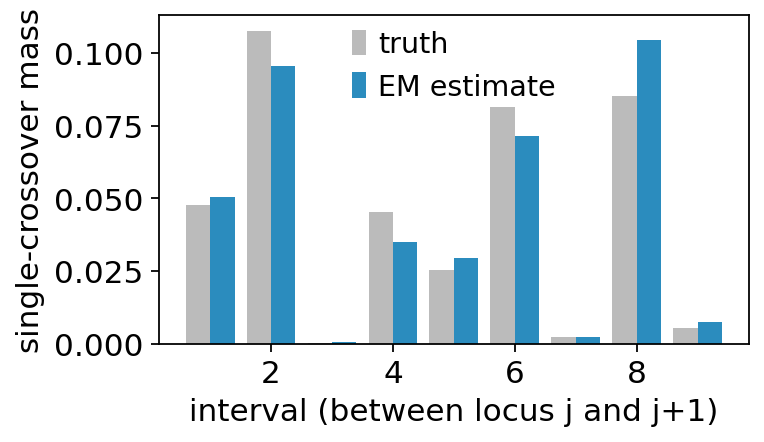

In [9]:
pairs = {(p["family_id"], p["role"]): (p["hap_a"], p["hap_b"]) for p in people}
par, trans, fids = [], [], []
for c in sim["children"]:
    for role, key in (("maternal", "maternal_transmitted"), ("paternal", "paternal_transmitted")):
        par.append(pairs[(c["family_id"], role)])
        trans.append(c[key])
        fids.append(c["family_id"])
rec = ov.genetics.fit_crossover_intervals(par, trans, fids)
print(f"no-crossover mass: estimate {rec['no_crossover']:.3f}  truth {sim['crossover']['no_crossover']:.3f}")
fig, ax = plt.subplots(figsize=(5, 3))
j = np.arange(1, len(rec["interval_masses"]) + 1)
ax.bar(j - 0.2, sim["crossover"]["interval_masses"], width=0.4, color="#bbbbbb", label="truth")
ax.bar(j + 0.2, rec["interval_masses"], width=0.4, color="#2b8cbe", label="EM estimate")
ax.set_xlabel("interval (between locus j and j+1)")
ax.set_ylabel("single-crossover mass")
ax.legend(frameon=False)
plt.tight_layout()

The transmitted sequences of a crossover need not be population
haplotypes: `gamete_sequences` lists every sequence a parent can transmit
with at most *k* crossovers, and `gamete_distribution` gives their
probabilities under the fitted masses. Anything conditional on a parental
state — the chance that a child inherits a risk haplotype, the likelihood of
a sibship's outcomes — follows from these and needs no catalog: compute it
from the state's own sequences, even for a haplotype never seen in the
phase-validated sample.

In [10]:
print(ov.genetics.gamete_sequences("000111", "110000", max_crossovers=1))
h1, h2 = "0" * 10, "1" * 10           # not in the catalog: still well defined
seqs, prob = ov.genetics.gamete_distribution(h1, h2, rec["no_crossover"], rec["interval_masses"])
print(f"{len(seqs)} transmitted sequences, total probability {prob.sum():.3f}")
print("P(child receives the allele at locus 1):",
      round(float(sum(p for s, p in zip(seqs, prob) if s[0] == "1")), 3),
      "  at locus 10:", round(float(sum(p for s, p in zip(seqs, prob) if s[-1] == "1")), 3))

['000000', '000100', '000110', '000111', '010000', '100111', '110000', '110001', '110011', '110111']
20 transmitted sequences, total probability 1.000
P(child receives the allele at locus 1): 0.5   at locus 10: 0.5


`offspring_outcome_probability` averages any outcome model of the two
transmitted sequences over both meioses — here a logistic penetrance with a
maternal and a paternal risk allele and their interaction. For a family whose
aggregate history is *k* affected among *n* conceptuses, the history's
probability given that state is Binomial(*k*; *n*, *q*).

In [11]:
from scipy.stats import binom


def penetrance(gm, gp):
    z = -3.0 + 1.2 * int(gm[0]) + 0.8 * int(gp[3]) + 1.5 * int(gm[0]) * int(gp[3])
    return 1.0 / (1.0 + np.exp(-z))


state_m, state_f = ("1000000000", "0000000000"), ("0001000000", "0001100000")
q = ov.genetics.offspring_outcome_probability(state_m, state_f, penetrance, rec, rec)
print(f"per-conceptus risk for this state: {q:.4f};  P(2 affected of 6 | state) = {binom.pmf(2, 6, q):.4f}")

per-conceptus risk for this state: 0.3611;  P(2 affected of 6 | state) = 0.3259


## 5. The structural identifiability certificate

Genotype assays give a likelihood triplet per locus (copy number 0 / 1 / 2)
or a no-call. A locus becomes a *hard* constraint only when the evidence is
decisive: the largest value reaches a minimum and exceeds the runner-up by a
minimum ratio (`confident_copy_calls`; both thresholds come from the study
protocol — there are no defaults). A family is **IDENTIFIABLE** when exactly
one joint state (mother diplotype, father diplotype; homologue swaps
equivalent) from the catalog satisfies every parental constraint and, for
every child, at least one pair of gametes with at most one crossover
reproduces the child's constrained copy numbers.

We simulate assay triplets (noisy, with no-calls) for a few families. Real
assay exports are long tables (one row per sample and locus with a call
status and three likelihoods); `genotype_likelihood_arrays` turns them into
per-sample arrays — build one dictionary over *all* tables (parents and
children), so every person is found by id:

In [12]:
rows_long = [("mother1", "L1", "CALLED", 0.01, 0.98, 0.01), ("mother1", "L2", "NO_CALL", "", "", ""),
             ("child1", "L1", "CALLED", 0.90, 0.10, 0.0), ("child1", "L2", "CALLED", 0.0, 0.30, 0.70)]
lik_by_sample = ov.genetics.genotype_likelihood_arrays(*zip(*rows_long), loci_order=["L1", "L2"])
for sid, (lik, called) in lik_by_sample.items():
    print(sid, called, ov.genetics.confident_copy_calls(lik, called, min_probability=0.72, min_ratio=3.0))

mother1 [ True False] [ 1 -1]
child1 [ True  True] [ 0 -1]


In [13]:
def assay(copy, rng, noise=0.25, no_call=0.15):
    lik = np.full((len(copy), 3), np.nan)
    called = rng.random(len(copy)) >= no_call
    for l, c in enumerate(copy):
        if called[l]:
            v = rng.dirichlet(np.ones(3)) * rng.uniform(0, 2 * noise)
            v[c] += 1.0
            lik[l] = v / v.max()
    return lik, called


rng = np.random.default_rng(5)
catalog = prior.catalog            # the phase-validated catalog
kids = {}
for c in sim["children"]:
    kids.setdefault(c["family_id"], []).append(c["copy_number"])
rows, evidence = [], {}
for fid in list(kids)[:60]:
    m, f = pairs[(fid, "maternal")], pairs[(fid, "paternal")]
    if not all(h in catalog for h in m + f):
        continue
    cc = lambda copy: ov.genetics.confident_copy_calls(*assay(copy, rng), min_probability=0.8,
                                                       min_ratio=3.0)
    copy = lambda pair: np.array([int(a) + int(b) for a, b in zip(*pair)])
    mc, fc = cc(copy(m)), cc(copy(f))
    kc = [cc(k) for k in kids[fid]]
    evidence[fid] = (mc, fc, kc)
    label, n = ov.genetics.structural_identifiability(catalog, mc, fc, kc, max_crossovers=1)
    _, n0 = ov.genetics.structural_identifiability(catalog, mc, fc, [], max_crossovers=1)
    rows.append({"family": fid, "children": len(kc),
                 "mother_compatible": len(ov.genetics.compatible_diplotypes(catalog, mc)),
                 "father_compatible": len(ov.genetics.compatible_diplotypes(catalog, fc)),
                 "states_parents_only(<=2)": n0, "states_with_children(<=2)": n,
                 "label": label})
cert = pd.DataFrame(rows)
print(cert["label"].value_counts().to_dict())
print("families made identifiable by their children:",
      int(((cert["states_parents_only(<=2)"] > 1) & (cert["label"] == "IDENTIFIABLE")).sum()))
cert.head(10)

{'IDENTIFIABLE': 39, 'AMBIGUOUS': 21}
families made identifiable by their children: 6


   family  children  mother_compatible  father_compatible  \
0  F00002         2                  5                  1   
1  F00003         1                  1                  1   
2  F00004         2                  4                  1   
3  F00009         2                  1                  1   
4  F00013         1                  1                  1   
5  F00014         1                  2                  1   
6  F00017         1                  1                  1   
7  F00021         2                  1                  3   
8  F00022         1                  1                  1   
9  F00024         2                  1                  1   

   states_parents_only(<=2)  states_with_children(<=2)         label  
0                         2                          2     AMBIGUOUS  
1                         1                          1  IDENTIFIABLE  
2                         2                          2     AMBIGUOUS  
3                         1                 

With no-calls and low-confidence loci a parent who is heterozygous at
several loci keeps several compatible phasings; the children's transmitted
haplotypes are what tells them apart. With `return_states=True` the function
returns every compatible state, which is how an AMBIGUOUS call is explained:

In [14]:
amb = cert.loc[cert["label"] == "AMBIGUOUS", "family"]
fid = amb.iloc[0] if len(amb) else cert["family"].iloc[0]
mc, fc, kc = evidence[fid]
label, n, states = ov.genetics.structural_identifiability(catalog, mc, fc, kc, return_states=True)
print(fid, label, f"{n} compatible joint states, e.g.:")
for (a, b), (c, d) in states[:3]:
    print("  mother", (catalog[a], catalog[b]), " father", (catalog[c], catalog[d]))
print("true state:  mother", pairs[(fid, "maternal")], " father", pairs[(fid, "paternal")])

F00002 AMBIGUOUS 2 compatible joint states, e.g.:
  mother ('0000100101', '1000001010')  father ('0000110000', '1000001010')
  mother ('0000101000', '1000000101')  father ('0000110000', '1000001010')
true state:  mother ('0000100101', '1000001010')  father ('0000110000', '1000001010')


## 6. Shipping the method in a pipeline that runs without omicverse

Clinical and benchmark pipelines are often re-executed in a minimal
environment (numpy / scipy only). The core of everything above is one file;
write it next to the script and import it from there:

In [15]:
import tempfile, importlib.util, pathlib
d = pathlib.Path(tempfile.mkdtemp())
ov.genetics.pedigree_core_source(d / "pedigree_core.py")
spec = importlib.util.spec_from_file_location("pedigree_core", d / "pedigree_core.py")
pc = importlib.util.module_from_spec(spec)
spec.loader.exec_module(pc)
print([n for n in pc.__all__])

['two_phase_weights', 'haplotype_frequencies', 'fit_haplotype_prior', 'HaplotypePrior', 'gamete_sequences', 'gamete_distribution', 'genotype_likelihood_arrays', 'offspring_outcome_probability', 'fit_crossover_intervals', 'confident_copy_calls', 'compatible_diplotypes', 'structural_identifiability', 'canonical_pair', 'simulate_family_cohort']


```python
# analyze.py, shipped together with pedigree_core.py
import sys, pathlib
sys.path.insert(0, str(pathlib.Path(__file__).resolve().parent))
import pedigree_core as pc
prior = pc.fit_haplotype_prior(...)   # same API as ov.genetics
```

## Pitfalls

* **Unweighted validated families** estimate the recruited population, not
  the source population. Weight by both phases.
* **Inclusion / validation probabilities, assay protocol or call rates as
  prior covariates** — they describe the observation process, not the
  population; use them as weights or in the assay likelihood.
* **Independent parents.** Multiplying two marginal priors ignores the
  shared founder class; use `conditional_diplotype_prob` /
  `joint_diplotype_prior`.
* **Growing the catalog from unphased genotypes** adds phase-switched or
  recombinant sequences that are not population haplotypes and changes both
  priors and certificates.
* **MAP instead of a certificate.** A confident posterior can coexist with
  several compatible states (the prior breaks the tie); the certificate only
  counts states compatible with hard evidence.

## References

* Horvitz DG, Thompson DJ (1952) A generalization of sampling without
  replacement from a finite universe. *JASA* 47:663–685.
* Hájek J (1971) Comment on a paper by D. Basu. In *Foundations of
  Statistical Inference*.
* Breslow NE, Wellner JA (2007) Weighted likelihood for semiparametric models
  and two-phase stratified samples. *Scand J Stat* 34:86–102.
* Excoffier L, Slatkin M (1995) Maximum-likelihood estimation of molecular
  haplotype frequencies in a diploid population. *Mol Biol Evol* 12:921–927.
* Lander ES, Green P (1987) Construction of multilocus genetic linkage maps
  in humans. *PNAS* 84:2363–2367.
* Pritchard JK, Stephens M, Donnelly P (2000) Inference of population
  structure using multilocus genotype data. *Genetics* 155:945–959.